# MVP — Análise de Dados e Boas Práticas

**Movimentação de óleo diesel A S10 em terminais aquaviários do Sudeste, 2025**

MBA PUC-Rio · Versão de trabalho · Validação inicial da base

# 1. Problema e perguntas

O objetivo é descrever os fluxos de recepção e entrega de diesel A S10 informados pelos terminais do Sudeste em 2025. A unidade de observação é um registro mensal de volume para uma combinação de terminal, produto, sentido, tipo de operação e modo de transporte. A unicidade dessa combinação será verificada na análise exploratória.

- **H1.** Como o volume mensal de recepção aquaviária de diesel A S10 se distribuiu entre os terminais do Sudeste em 2025?
- **H2.** Qual foi a participação de cada modo de transporte nas entregas de diesel A S10 registradas, por terminal com entregas reportadas?

A análise é descritiva e mantém recepções e entregas separadas. A base reserva é a série mensal de vendas de derivados e etanol da ANP.

# 2. Fonte e significado dos dados

[Movimentação dos Terminais Aquaviários — ANP](https://www.gov.br/anp/pt-br/centrais-de-conteudo/dados-abertos/movimentacao-dos-terminais-aquaviarios) · [Dicionário oficial](https://www.gov.br/anp/pt-br/centrais-de-conteudo/dados-abertos/arquivos/arquivos-movimentacao-dos-terminais-aquaviarios/metadados-movimentacao-terminais-aquaviarios.pdf)

A carga usa o arquivo público da ANP. A fonte pode ser atualizada. O código registra o SHA-256 para identificar os bytes usados em cada execução. A política de redistribuição e o procedimento de fixação da versão serão verificados antes da entrega.

| Variável | Significado | Tipo / unidade |
|---|---|---|
| mes_de_referencia | Mês de referência | Data mensal |
| codigo_anp_do_terminal | Identificador do estabelecimento na ANP | Código |
| uf | UF do terminal | Categoria |
| sentido_da_operacao | Recepção (1) ou entrega (2) | Código |
| tipo_da_operacao | Categoria da operação, conforme dicionário | Código |
| modo_de_transporte | Rodoviário (1), ferroviário (2), aquaviário (4), dutoviário (5) ou outros (9) | Código |
| codigo_anp_do_produto | Identificador do produto | Código |
| descricao_do_produto | Descrição informada do produto | Texto |
| volume_m3 | Volume informado a 20 °C | m³ |

# 3. Ambiente e carregamento

Execute as células em ordem com Python, pandas e openpyxl. A fonte é baixada sem autenticação. O formato é identificado pelos bytes do arquivo, pois a extensão publicada pode divergir do conteúdo.

In [1]:
from hashlib import sha256
from importlib.metadata import version
from io import BytesIO
import sys
from urllib.request import urlopen

import pandas as pd

URL_ANP = (
    "https://www.gov.br/anp/pt-br/centrais-de-conteudo/dados-abertos/"
    "arquivos/arquivos-movimentacao-dos-terminais-aquaviarios/"
    "dados-abertos-movimentacao-terminais-aquaviarios.csv"
)

print("Python", sys.version.split()[0])
for pacote in ("pandas", "openpyxl"):
    print(pacote, version(pacote))

with urlopen(URL_ANP, timeout=60) as resposta:
    arquivo = resposta.read()

print("SHA-256", sha256(arquivo).hexdigest())

if arquivo.startswith(b"PK\x03\x04"):
    dados_origem = pd.read_excel(BytesIO(arquivo), engine="openpyxl")
    print("Formato recebido: Excel")
else:
    dados_origem = pd.read_csv(
        BytesIO(arquivo), sep=";", decimal=",", encoding="utf-8-sig"
    )
    print("Formato recebido: CSV")

dados = dados_origem.rename(
    columns=lambda nome: nome.strip().lower()
).rename(columns={"mesreferencia": "mes_de_referencia"})

colunas_necessarias = {
    "mes_de_referencia", "codigo_anp_do_terminal", "uf",
    "sentido_da_operacao", "tipo_da_operacao", "modo_de_transporte",
    "codigo_anp_do_produto", "descricao_do_produto", "volume_m3",
}
faltantes = colunas_necessarias.difference(dados.columns)
if faltantes:
    raise ValueError(f"Colunas esperadas ausentes: {sorted(faltantes)}")

mes = pd.to_datetime(dados["mes_de_referencia"], format="mixed", errors="coerce")
if (mes.isna() & dados["mes_de_referencia"].notna()).any():
    raise ValueError("Há meses de referência em formato inesperado.")

sudeste_2025 = dados.loc[
    mes.dt.year.eq(2025) & dados["uf"].isin(["ES", "MG", "RJ", "SP"])
].copy()
sudeste_2025["mes_de_referencia"] = mes.loc[sudeste_2025.index].dt.to_period("M")
if sudeste_2025["mes_de_referencia"].nunique() != 12:
    raise ValueError("O recorte regional não contém os 12 meses de 2025.")

codigo_produto = pd.to_numeric(sudeste_2025["codigo_anp_do_produto"], errors="coerce")
diesel_s10 = sudeste_2025.loc[codigo_produto.eq(420105001)].copy()
if diesel_s10.empty:
    raise ValueError("O produto 420105001 não foi encontrado no recorte.")

Python 3.13.18
pandas 2.2.3
openpyxl 3.1.5
SHA-256 5e4a123e8013fc9b36bfe54a58a4d8bcb7f5332eef89b7ec8e309cd92e0edc86
Formato recebido: Excel


# 4. Análise exploratória

Checagem inicial de cobertura e descrições do produto.

In [2]:
resumo_carga = pd.DataFrame({
    "Registros": [len(dados_origem), len(sudeste_2025), len(diesel_s10)],
    "Terminais": [
        dados["codigo_anp_do_terminal"].nunique(),
        sudeste_2025["codigo_anp_do_terminal"].nunique(),
        diesel_s10["codigo_anp_do_terminal"].nunique(),
    ],
}, index=["Arquivo de origem", "Sudeste em 2025", "Diesel A S10 no recorte"])

display(resumo_carga)
display(diesel_s10["descricao_do_produto"].value_counts(dropna=False))

,Registros,Terminais
Arquivo de origem,190944,130
Sudeste em 2025,6891,23
Diesel A S10 no recorte,1843,13


,count
descricao_do_produto,
Ã“LEO DIESEL A S10,1352
ÓLEO DIESEL A S10,245
DIESEL S10,189
OLEO DIESEL A S 10,31
OLEO DIESEL S10,15
OLEO DIESEL A S10,11


## 4.1 Granularidade, ausências e cobertura

A chave candidata serve para investigar repetições. A tabela de cobertura conta registros por terminal e mês. Zero na tabela indica ausência de registros no recorte.

In [3]:
chave_candidata = [
    "mes_de_referencia", "codigo_anp_do_terminal", "codigo_anp_do_produto",
    "sentido_da_operacao", "tipo_da_operacao", "modo_de_transporte",
]

ausencias = diesel_s10.isna().sum().rename("ausências")
display(pd.concat([diesel_s10.dtypes.rename("tipo"), ausencias], axis=1))

print("Duplicatas exatas além da primeira ocorrência:", diesel_s10.duplicated().sum())
repeticoes = diesel_s10.duplicated(subset=chave_candidata, keep=False)
print("Registros em chaves candidatas repetidas:", repeticoes.sum())
if repeticoes.any():
    display(
        diesel_s10.loc[repeticoes]
        .groupby(chave_candidata, dropna=False)
        .agg(registros=("volume_m3", "size"), volumes_distintos=("volume_m3", "nunique"))
        .sort_values("registros", ascending=False)
        .head(10)
    )

meses_2025 = pd.period_range("2025-01", "2025-12", freq="M")
cobertura = (
    diesel_s10.groupby(["codigo_anp_do_terminal", "mes_de_referencia"])
    .size()
    .unstack(fill_value=0)
    .reindex(columns=meses_2025, fill_value=0)
)
display(cobertura.assign(meses_com_registro=cobertura.gt(0).sum(axis=1)))

,tipo,ausências
mes_de_referencia,period[M],0
codigo_anp_do_terminal,int64,0
nome_do_terminal,object,0
municipio_do_terminal,object,0
uf,object,0
sentido_da_operacao,int64,0
tipo_da_operacao,int64,0
modo_de_transporte,int64,0
codigo_anp_do_produto,int64,0
descricao_do_produto,object,0


Duplicatas exatas além da primeira ocorrência: 6
Registros em chaves candidatas repetidas: 1532


,,,,,,registros,volumes_distintos
mes_de_referencia,codigo_anp_do_terminal,codigo_anp_do_produto,sentido_da_operacao,tipo_da_operacao,modo_de_transporte,,
2025-12,1205529,420105001,2,1,1,179,179
2025-11,1205529,420105001,2,1,1,134,133
2025-10,1205529,420105001,2,1,1,132,131
2025-05,1205529,420105001,2,1,1,119,119
2025-06,1205529,420105001,2,1,1,113,113
2025-04,1205529,420105001,2,1,1,103,103
2025-09,1205529,420105001,2,1,1,93,92
2025-07,1205529,420105001,2,1,1,70,70
2025-03,1205529,420105001,2,1,1,69,69


,2025-01,2025-02,2025-03,2025-04,2025-05,2025-06,2025-07,2025-08,2025-09,2025-10,2025-11,2025-12,meses_com_registro
codigo_anp_do_terminal,,,,,,,,,,,,,
1032193,2,2,2,2,2,2,2,2,2,2,2,2,12
1032194,3,1,1,2,4,0,1,1,0,4,1,0,9
1032197,4,4,4,3,6,5,6,6,5,5,5,6,12
1032198,3,3,3,4,3,3,3,3,3,3,3,3,12
1032236,2,3,2,3,3,3,3,2,3,2,3,2,12
1041860,2,2,2,2,2,2,2,2,2,2,1,2,12
1043387,14,11,16,16,18,18,17,16,18,14,16,15,12
1107648,2,2,2,2,2,2,2,2,2,2,2,2,12
1109984,0,0,0,2,1,2,1,1,1,2,1,0,8


## 4.2 Sensibilidade a registros idênticos

A comparação mede o efeito de retirar cópias exatas dentro do recorte. Os dois cenários são calculados sem alterar os dados usados nas outras células.

In [4]:
candidatas_exatas = diesel_s10.duplicated(keep=False)
display(
    diesel_s10.loc[candidatas_exatas, chave_candidata + ["volume_m3"]]
    .sort_values(chave_candidata + ["volume_m3"])
)

comparacao = pd.concat(
    [
        diesel_s10.groupby("sentido_da_operacao")["volume_m3"].sum(min_count=1)
        .rename("volume_com_todas_m3"),
        diesel_s10.drop_duplicates().groupby("sentido_da_operacao")["volume_m3"]
        .sum(min_count=1).rename("volume_sem_copias_exatas_m3"),
    ],
    axis=1,
)
comparacao["diferenca_m3"] = (
    comparacao["volume_com_todas_m3"] - comparacao["volume_sem_copias_exatas_m3"]
)
display(comparacao.rename(index={1: "Recepção", 2: "Entrega"}))

,mes_de_referencia,codigo_anp_do_terminal,codigo_anp_do_produto,sentido_da_operacao,tipo_da_operacao,modo_de_transporte,volume_m3
188836,2025-03,1043387,420105001,1,1,9,0.001
188837,2025-03,1043387,420105001,1,1,9,0.001
188845,2025-05,1043387,420105001,1,1,9,0.001
188847,2025-05,1043387,420105001,1,1,9,0.001
188854,2025-07,1043387,420105001,1,1,9,0.001
188858,2025-07,1043387,420105001,1,1,9,0.001
109619,2025-09,1205529,420105001,2,1,1,57.300
109623,2025-09,1205529,420105001,2,1,1,57.300
110861,2025-10,1205529,420105001,2,1,1,61.790
110876,2025-10,1205529,420105001,2,1,1,61.790


,volume_com_todas_m3,volume_sem_copias_exatas_m3,diferenca_m3
sentido_da_operacao,,,
Recepção,8889369.830,8889369.827,0.003
Entrega,8826921.906,8826745.836,176.070


## 4.3 Estatísticas, consistência e valores extremos

As estatísticas descrevem o volume por registro. As frequências contam linhas por categoria. A triagem sinaliza volumes abaixo de Q1 ou acima de Q3 por mais de 1,5 vezes a amplitude interquartil, dentro de cada combinação de sentido e modo. Grupos pequenos ou de amplitude zero exigem cautela. A sinalização orienta a inspeção dos valores e não implica remoção.

In [5]:
display(diesel_s10.head())
volume = diesel_s10["volume_m3"]
display(volume.agg(["count", "min", "max", "median", "mean", "std"]).round(3).to_frame())
print("Ausências de volume:", volume.isna().sum())
frequencias_volume = volume.value_counts()
print("Moda(s) em m³:", volume.mode().tolist() if frequencias_volume.max() > 1 else "sem valor repetido")

dominios = {
    "sentido_da_operacao": {1, 2},
    "tipo_da_operacao": {1, 2, 3, 4, 9},
    "modo_de_transporte": {1, 2, 4, 5, 9},
}
for coluna in ("uf", *dominios):
    display(diesel_s10[coluna].value_counts(dropna=False).rename("registros").to_frame())

infinitos = volume.isin([float("inf"), -float("inf")])
checagens = {
    f"Códigos fora do dicionário: {coluna}":
        (diesel_s10[coluna].notna() & ~diesel_s10[coluna].isin(dominio)).sum()
    for coluna, dominio in dominios.items()
}
checagens.update({"Volumes infinitos": infinitos.sum(),
                  "Volumes negativos": volume.lt(0).sum(),
                  "Volumes iguais a zero": volume.eq(0).sum()})
display(pd.Series(checagens, name="registros").to_frame())

grupos = ["sentido_da_operacao", "modo_de_transporte"]
triagem = diesel_s10.loc[volume.notna() & ~infinitos, grupos + ["volume_m3"]].copy()
v = triagem["volume_m3"]
agrupado = triagem.groupby(grupos)["volume_m3"]
q1 = agrupado.transform("quantile", q=0.25)
q3 = agrupado.transform("quantile", q=0.75)
amplitude = q3 - q1
triagem["sinalizado_iqr"] = v.lt(q1 - 1.5 * amplitude) | v.gt(q3 + 1.5 * amplitude)
resumo_extremos = triagem.groupby(grupos).agg(
    registros=("volume_m3", "size"),
    minimo_m3=("volume_m3", "min"),
    mediana_m3=("volume_m3", "median"),
    maximo_m3=("volume_m3", "max"),
    sinalizados=("sinalizado_iqr", "sum"),
)
display(resumo_extremos.round(3))

,mes_de_referencia,codigo_anp_do_terminal,nome_do_terminal,municipio_do_terminal,uf,sentido_da_operacao,tipo_da_operacao,modo_de_transporte,codigo_anp_do_produto,descricao_do_produto,sentido_modal,volume_m3,nome_da_instalacao
1529,2025-01,1032197,TA S.SEBASTIAO,SAO SEBASTIAO,SP,1,1,4,420105001,ÓLEO DIESEL A S10,Recepção - Aquaviário,516.891,TRANSPETRO SÃO SEBASTIÃO
1530,2025-02,1032197,TA S.SEBASTIAO,SAO SEBASTIAO,SP,1,1,4,420105001,ÓLEO DIESEL A S10,Recepção - Aquaviário,126788.499,TRANSPETRO SÃO SEBASTIÃO
1531,2025-03,1032197,TA S.SEBASTIAO,SAO SEBASTIAO,SP,1,1,4,420105001,ÓLEO DIESEL A S10,Recepção - Aquaviário,312.599,TRANSPETRO SÃO SEBASTIÃO
1532,2025-05,1032197,TA S.SEBASTIAO,SAO SEBASTIAO,SP,1,1,4,420105001,ÓLEO DIESEL A S10,Recepção - Aquaviário,120447.006,TRANSPETRO SÃO SEBASTIÃO
1533,2025-06,1032197,TA S.SEBASTIAO,SAO SEBASTIAO,SP,1,1,4,420105001,ÓLEO DIESEL A S10,Recepção - Aquaviário,115025.252,TRANSPETRO SÃO SEBASTIÃO


,volume_m3
count,1843.000
min,0.000
max,395584.916
median,648.130
mean,9612.746
std,30299.876


Ausências de volume: 0
Moda(s) em m³: [0.001]


,registros
uf,
SP,1765
ES,60
RJ,18


,registros
sentido_da_operacao,
2,1404
1,439


,registros
tipo_da_operacao,
1,1782
9,28
2,17
3,16


,registros
modo_de_transporte,
1,1300
4,365
9,121
5,57


,registros
Códigos fora do dicionário: sentido_da_operacao,0
Códigos fora do dicionário: tipo_da_operacao,0
Códigos fora do dicionário: modo_de_transporte,0
Volumes infinitos,0
Volumes negativos,0
Volumes iguais a zero,7


registros  minimo_m3  mediana_m3  \
sentido_da_operacao modo_de_transporte                                     
1                   1                          34      0.000     151.270   
                    4                         321     17.830    5030.142   
                    5                          29      0.001   44063.509   
                    9                          55      0.001    3500.000   
2                   1                        1266      2.220     350.255   
                    4                          44    345.574   25238.566   
                    5                          28      0.001   27869.396   
                    9                          66      0.001     101.676   

                                         maximo_m3  sinalizados  
sentido_da_operacao modo_de_transporte                           
1                   1                    15397.010            3  
                    4                   384962.097           31  
                    5                   160070.117            0  
                    9                   185000.914            8  
2                   1                    77502.620          151  
                    4                   186536.127            0  
                    5                   395584.916            3  
                    9                   185000.914            9

### 4.4 Inspeção dos zeros e dos maiores volumes sinalizados

As tabelas identificam os registros pelo terminal, mês e operação. A inspeção usa os dados originais do recorte e preserva os volumes informados.

In [6]:
campos_inspecao = [
    "mes_de_referencia", "codigo_anp_do_terminal", "nome_do_terminal",
    "sentido_da_operacao", "tipo_da_operacao", "modo_de_transporte", "volume_m3",
]

print("Registros com volume zero")
display(diesel_s10.loc[volume.eq(0), campos_inspecao].sort_values(
    ["codigo_anp_do_terminal", "mes_de_referencia"]
))

print("Até três maiores volumes sinalizados por sentido e modo")
maiores_sinalizados = (
    triagem.loc[triagem["sinalizado_iqr"]]
    .sort_values("volume_m3", ascending=False)
    .groupby(grupos, sort=False)
    .head(3)
)
display(diesel_s10.loc[maiores_sinalizados.index, campos_inspecao].sort_values(
    grupos + ["volume_m3"], ascending=[True, True, False]
))

Registros com volume zero


,mes_de_referencia,codigo_anp_do_terminal,nome_do_terminal,sentido_da_operacao,tipo_da_operacao,modo_de_transporte,volume_m3
169743,2025-01,1156832,Oiltanking Terminais,1,1,1,0.0
169747,2025-05,1156832,Oiltanking Terminais,1,1,1,0.0
169749,2025-07,1156832,Oiltanking Terminais,1,1,1,0.0
169441,2025-11,1156832,OTAMERICA Terminais,1,1,1,0.0
167290,2025-07,1262998,TERMINAL GRANEL QUIMICA,1,1,1,0.0
167291,2025-08,1262998,TERMINAL GRANEL QUIMICA,1,1,1,0.0
167292,2025-09,1262998,TERMINAL GRANEL QUIMICA,1,1,1,0.0


Até três maiores volumes sinalizados por sentido e modo


,mes_de_referencia,codigo_anp_do_terminal,nome_do_terminal,sentido_da_operacao,tipo_da_operacao,modo_de_transporte,volume_m3
166336,2025-04,1032236,STOLTHAVEN SANTOS LTDA.,1,1,1,15397.010
166354,2025-11,1032236,STOLTHAVEN SANTOS LTDA.,1,1,1,10836.550
166333,2025-02,1032236,STOLTHAVEN SANTOS LTDA.,1,1,1,9999.480
1537,2025-10,1032197,TA S.SEBASTIAO,1,1,4,384962.097
1536,2025-09,1032197,TA S.SEBASTIAO,1,1,4,363887.332
1538,2025-11,1032197,TA S.SEBASTIAO,1,1,4,345628.844
188871,2025-10,1043387,VOPAK BRASIL S/A - ALEMOA,1,1,9,185000.914
188839,2025-04,1043387,VOPAK BRASIL S/A - ALEMOA,1,1,9,126034.232
188843,2025-05,1043387,VOPAK BRASIL S/A - ALEMOA,1,1,9,112320.319
179260,2025-09,1107648,AGEO,2,1,1,77502.620


**Leitura do diagnóstico.** Os zeros desta tabela são volumes informados em linhas existentes. A ausência de registro na tabela de cobertura indica que não há linha para a combinação analisada. A regra interquartil sinaliza valores para inspeção dentro de cada grupo. A tabela exibe até três dos maiores valores sinalizados por grupo. Para verificar se linhas com o mesmo volume são idênticas, compare também o sentido da operação e os demais campos da seção 4.1.

# 5. Pré-processamento e decisões

As decisões abaixo definem os recortes de H1 e H2 para a análise descritiva. A divisão em treino e teste não se aplica, pois o trabalho não estima nem avalia um modelo preditivo.

## 5.1 D1. Seleção do produto

- **Evidência.** O código ANP `420105001` aparece associado a seis grafias no recorte de 2025 no Sudeste.
- **Alternativas e decisão.** Compararam-se a igualdade literal com `ÓLEO DIESEL A S10` e a seleção pelo código ANP no mesmo recorte geográfico e temporal. Adotou-se o código como identificador, pois ele reúne as variantes de descrição.
- **Verificação.** A descrição literal recuperou 245 dos 1.843 registros e todos os 245 pertencem ao código escolhido. A seleção pelo código recuperou 439 recepções e 1.404 entregas. A regra literal recuperou aproximadamente 70,6% do volume de recepção e 70,0% do volume de entrega obtidos pelo código.
- **Limite.** A regra depende da correção do código cadastrado na fonte. A comparação verifica a consistência entre os campos publicados.

In [ ]:
selecao_literal = sudeste_2025.loc[
    sudeste_2025["descricao_do_produto"].eq("ÓLEO DIESEL A S10")
]

print("Códigos ANP das linhas selecionadas por descrição literal:")
display(selecao_literal["codigo_anp_do_produto"].value_counts(dropna=False))

comparacao_filtros = pd.concat(
    [
        recorte.groupby("sentido_da_operacao").agg(
            registros=("volume_m3", "size"),
            volume_m3=("volume_m3", lambda volume: volume.sum(min_count=1)),
        )
        for recorte in (diesel_s10, selecao_literal)
    ],
    keys=["Código ANP", "Descrição literal"],
    names=["Regra", "Sentido"],
)
display(comparacao_filtros.rename(index={1: "Recepção", 2: "Entrega"}, level="Sentido"))

Códigos ANP das linhas selecionadas por descrição literal:


,count
codigo_anp_do_produto,
420105001,245


registros    volume_m3
Regra             Sentido                         
Código ANP        Recepção        439  8889369.830
                  Entrega        1404  8826921.906
Descrição literal Recepção        126  6271819.377
                  Entrega         119  6176508.241

## 5.2 D2. Registros idênticos nos recortes de H1 e H2

- **Evidência.** A seção 4.1 identificou seis cópias exatas além da primeira ocorrência. Também encontrou 1.532 registros em grupos que repetem a chave candidata, inclusive grupos com vários volumes distintos. A combinação de mês, terminal, produto, sentido, tipo de operação e modo serve para agrupar as linhas.
- **Alternativas e decisão.** Compararam-se a manutenção de todas as linhas e a exclusão das cópias exatas. Na análise principal, mantiveram-se os registros publicados, inclusive os sete volumes zero e os volumes sinalizados por intervalo interquartil. A fonte não fornece identificador individual da operação que permita confirmar duplicidade operacional, e o diagnóstico não estabeleceu erro nos zeros ou nos extremos inspecionados.
- **Verificação.** Excluir as cópias exatas não alterou os totais da recepção aquaviária por terminal em H1. Em H2, a diferença de 176,070 m³ ficou restrita ao terminal `1205529` e o percentual rodoviário permaneceu em 100%. A seção 4.2 apresenta, separadamente, o efeito sobre todas as recepções, incluindo os demais modos.
- **Limite.** A manutenção pode preservar duplicidades reais. O cenário alternativo quantifica o efeito das linhas idênticas, e a regra interquartil é usada como triagem.

In [ ]:
sem_copias = diesel_s10.drop_duplicates()
cenario_por_pergunta = []

for nome, sentido in [("H1 · Recepção aquaviária", 1), ("H2 · Entregas", 2)]:
    totais = []
    for dados_cenario in (diesel_s10, sem_copias):
        filtro = dados_cenario["sentido_da_operacao"].eq(sentido)
        if sentido == 1:
            filtro &= dados_cenario["modo_de_transporte"].eq(4)
        totais.append(
            dados_cenario.loc[filtro].groupby("codigo_anp_do_terminal")["volume_m3"]
            .sum(min_count=1)
        )
    por_terminal = pd.concat(totais, axis=1)
    por_terminal.columns = ["com_todas_m3", "sem_copias_m3"]
    por_terminal["diferença_m3"] = (
        por_terminal["com_todas_m3"] - por_terminal["sem_copias_m3"]
    ).round(3)
    por_terminal["pergunta"] = nome
    cenario_por_pergunta.append(por_terminal.reset_index())

impacto_d2 = pd.concat(cenario_por_pergunta, ignore_index=True)
display(impacto_d2[["pergunta", "codigo_anp_do_terminal", "com_todas_m3",
                   "sem_copias_m3", "diferença_m3"]])

,pergunta,codigo_anp_do_terminal,com_todas_m3,sem_copias_m3,diferença_m3
0,H1 · Recepção aquaviária,1032193,284950.024,284950.024,0.00
1,H1 · Recepção aquaviária,1032194,107139.131,107139.131,0.00
2,H1 · Recepção aquaviária,1032197,2579522.623,2579522.623,0.00
3,H1 · Recepção aquaviária,1032236,109457.460,109457.460,0.00
4,H1 · Recepção aquaviária,1041860,468794.360,468794.360,0.00
5,H1 · Recepção aquaviária,1043387,543823.303,543823.303,0.00
6,H1 · Recepção aquaviária,1107648,602034.547,602034.547,0.00
7,H1 · Recepção aquaviária,1109984,71800.320,71800.320,0.00
8,H1 · Recepção aquaviária,1156832,348371.889,348371.889,0.00
9,H1 · Recepção aquaviária,1205529,753584.970,753584.970,0.00


## 5.3 D3. Cobertura mensal da recepção aquaviária

- **Evidência.** Entre as 156 combinações de 13 terminais e 12 meses, 117 tinham ao menos um registro de recepção aquaviária e 39 estavam sem registro. Nenhuma das combinações observadas teve volume agregado igual a zero.
- **Alternativas e decisão.** Consideraram-se preencher as lacunas com zero ou manter o volume ausente. Adotou-se a segunda alternativa, pois o arquivo não documenta que a falta de uma linha equivale a volume zero.
- **Verificação.** A contagem distingue as combinações com e sem registro. A matriz mensal preserva as 156 combinações e apresenta as 39 lacunas em cinza na figura de H1. A regra vale para as lacunas do painel e preserva os zeros informados nas linhas de origem.
- **Limite.** A base não distingue ausência de movimentação de ausência de informação nas lacunas de H1.

In [ ]:
recepcao_aquaviaria = diesel_s10.loc[
    diesel_s10["sentido_da_operacao"].eq(1)
    & diesel_s10["modo_de_transporte"].eq(4)
]
terminais_recorte = pd.Index(
    sorted(diesel_s10["codigo_anp_do_terminal"].unique()),
    name="codigo_anp_do_terminal",
)
grupos_h1 = recepcao_aquaviaria.groupby(
    ["codigo_anp_do_terminal", "mes_de_referencia"]
)["volume_m3"]
volume_mensal_h1 = grupos_h1.sum(min_count=1).unstack().reindex(
    index=terminais_recorte, columns=meses_2025
)
contagem_h1 = grupos_h1.size().unstack().reindex(
    index=terminais_recorte, columns=meses_2025
).fillna(0).astype(int)

cobertura_h1 = pd.DataFrame({
    "meses_com_registro": contagem_h1.gt(0).sum(axis=1),
    "meses_sem_registro": contagem_h1.eq(0).sum(axis=1),
    "meses_com_volume_zero": volume_mensal_h1.eq(0).sum(axis=1),
})
display(cobertura_h1)

,meses_com_registro,meses_sem_registro,meses_com_volume_zero
codigo_anp_do_terminal,,,
1032193,12,0,0
1032194,6,6,0
1032197,11,1,0
1032198,0,12,0
1032236,9,3,0
1041860,11,1,0
1043387,12,0,0
1107648,12,0,0
1109984,3,9,0


## 5.4 Tabela e figura para H1

O gráfico usa a matriz mensal de D3. As linhas são identificadas pelo código ANP do terminal. Células cinza indicam ausência de registro de recepção aquaviária no recorte.

matplotlib 3.10.0


,2025-01,2025-02,2025-03,2025-04,2025-05,2025-06,2025-07,2025-08,2025-09,2025-10,2025-11,2025-12
codigo_anp_do_terminal,,,,,,,,,,,,
1032193,26888.095,14735.801,34467.308,20568.587,26331.504,13813.727,28512.270,23816.862,13323.482,26753.596,27811.876,27926.916
1032194,NaN,5448.346,NaN,15661.896,17599.718,NaN,NaN,5003.456,NaN,29762.782,33662.933,NaN
1032197,516.891,126788.499,312.599,NaN,244855.246,159974.687,247355.455,159006.081,498795.754,571498.224,409128.496,161290.691
1032198,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1032236,20025.010,6945.490,10504.680,25184.440,8728.440,14845.210,2662.630,NaN,5785.770,NaN,14775.790,NaN
1041860,1991.088,15255.653,42150.434,89465.317,57163.180,38081.045,54216.170,39923.881,79742.168,45379.994,NaN,5425.430
1043387,2980.278,22928.555,15304.029,84114.820,77027.286,46245.271,53638.038,35526.863,57867.733,85977.666,50058.922,12153.842
1107648,52670.486,61997.155,55278.020,64876.986,24364.298,53954.695,69898.587,75974.062,59923.367,50168.046,9980.213,22948.632
1109984,NaN,NaN,NaN,29945.270,NaN,36889.090,NaN,NaN,NaN,4965.960,NaN,NaN


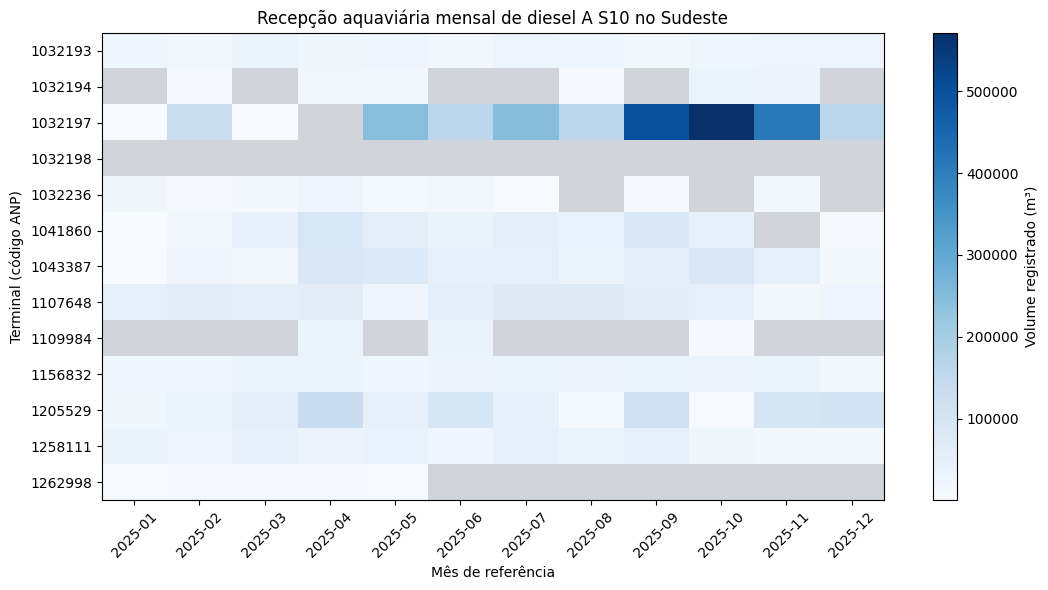

In [ ]:
import matplotlib.pyplot as plt

print("matplotlib", version("matplotlib"))
display(volume_mensal_h1.round(3))

fig, ax = plt.subplots(figsize=(11, 6))
imagem = ax.imshow(
    volume_mensal_h1.to_numpy(),
    aspect="auto",
    cmap=plt.get_cmap("Blues").with_extremes(bad="#d1d5db"),
)
ax.set_xticks(range(len(meses_2025)), [str(mes) for mes in meses_2025], rotation=45)
ax.set_yticks(range(len(terminais_recorte)), terminais_recorte.astype(str))
ax.set(title="Recepção aquaviária mensal de diesel A S10 no Sudeste",
       xlabel="Mês de referência", ylabel="Terminal (código ANP)")
fig.colorbar(imagem, ax=ax, label="Volume registrado (m³)")
fig.tight_layout()
plt.show()

## 5.5 Tabela e figura para H2

A participação de cada modo usa como denominador o volume total de entregas registradas no terminal. Um zero na distribuição indica que aquele modo não contribuiu para o volume registrado. Caso algum terminal tenha total zero, suas participações ficam indefinidas.

modo_de_transporte,Rodoviário,Aquaviário,Dutoviário,Outros,total_m3
codigo_anp_do_terminal,,,,,
1032193,0.000,0.000,284950.024,0.000,284950.024
1032194,0.000,19815.556,46783.608,0.000,66599.164
1032197,0.000,808835.186,2010402.756,0.000,2819237.942
1032198,0.000,1153299.498,0.000,0.000,1153299.498
1032236,169504.610,0.000,0.000,0.000,169504.610
1041860,494416.797,0.000,0.000,0.000,494416.797
1043387,603807.617,0.000,0.001,1049191.759,1652999.377
1107648,614137.972,0.000,0.000,0.000,614137.972
1109984,71742.970,0.000,0.000,0.000,71742.970


modo_de_transporte,Rodoviário,Aquaviário,Dutoviário,Outros
codigo_anp_do_terminal,,,,
1032193,0.00,0.00,100.00,0.00
1032194,0.00,29.75,70.25,0.00
1032197,0.00,28.69,71.31,0.00
1032198,0.00,100.00,0.00,0.00
1032236,100.00,0.00,0.00,0.00
1041860,100.00,0.00,0.00,0.00
1043387,36.53,0.00,0.00,63.47
1107648,100.00,0.00,0.00,0.00
1109984,100.00,0.00,0.00,0.00


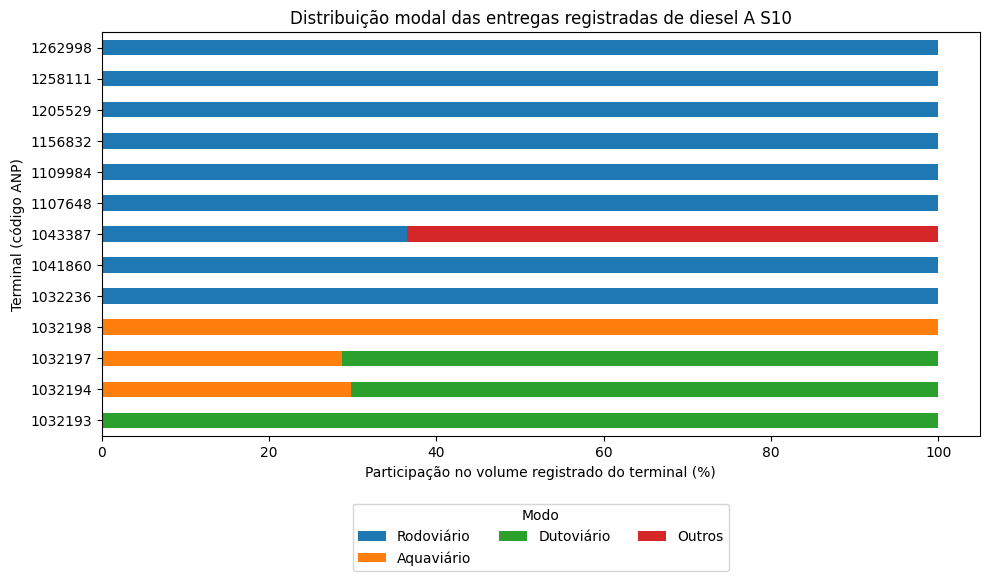

In [ ]:
entregas = diesel_s10.loc[diesel_s10["sentido_da_operacao"].eq(2)]
volume_entregas_h2 = (
    entregas.groupby(["codigo_anp_do_terminal", "modo_de_transporte"])["volume_m3"]
    .sum(min_count=1)
    .unstack(fill_value=0)
    .rename(columns={1: "Rodoviário", 2: "Ferroviário", 4: "Aquaviário",
                     5: "Dutoviário", 9: "Outros"})
)
total_entregas = volume_entregas_h2.sum(axis=1, min_count=1)
participacao_h2 = volume_entregas_h2.div(total_entregas.where(total_entregas.ne(0)), axis=0) * 100
display(volume_entregas_h2.assign(total_m3=total_entregas).round(3))
display(participacao_h2.round(2))

ax = participacao_h2.dropna(how="all").plot.barh(stacked=True, figsize=(10, 6))
ax.set(title="Distribuição modal das entregas registradas de diesel A S10",
       xlabel="Participação no volume registrado do terminal (%)",
       ylabel="Terminal (código ANP)")
ax.legend(title="Modo", loc="upper center", bbox_to_anchor=(0.5, -0.15), ncol=3)
ax.figure.tight_layout()
plt.show()

# 6. Respostas e conclusão

## H1. Recepção aquaviária mensal

Em 2025, o terminal `1032197` (Terminal Aquaviário de São Sebastião, TEBAR), em São Sebastião (SP), registrou **2.579.522,623 m³** de recepção aquaviária de óleo diesel A S10. Foi o maior volume entre os terminais do Sudeste no recorte e correspondeu a **41,11%** dos **6.273.958,061 m³** registrados na região. Os três maiores volumes mensais do TEBAR ocorreram em setembro (**498.795,754 m³**), outubro (**571.498,224 m³**) e novembro (**409.128,496 m³**). Esses meses somaram **57,35%** da recepção aquaviária anual registrada no terminal, conforme a tabela e o mapa de calor da seção 5.4.

O terminal teve registros em 11 dos 12 meses. Abril ficou sem registro de recepção aquaviária. Os dados descrevem a movimentação reportada à ANP e não identificam a origem importada ou doméstica do diesel, seu destino final nem os fatores que explicam o pico. A possível associação com a sazonalidade do agronegócio e do transporte rodoviário de cargas pode ser investigada com séries de demanda e movimentação de vários anos.

## H2. Distribuição modal das entregas

Os 13 terminais registraram **8.826.921,91 m³** em entregas de diesel A S10. Dez registraram entregas por um único modo e três por mais de um. Em oito terminais, o rodoviário representou **100,00%** do volume entregue. Entre eles, o `1262998` (Granel Química Santos) registrou **25.496,09 m³** e o `1205529` (Ultracargo Santos), **730.670,62 m³**. Os outros dois terminais com um único modo registrado foram o `1032198` (Transpetro Santos), com **1.153.299,50 m³** por via aquaviária, e o `1032193` (Transpetro Vitória), com **284.950,02 m³** por dutos.

O maior volume de entregas foi o do `1032197` (Terminal Aquaviário de São Sebastião, TEBAR), com **2.819.237,94 m³**. A distribuição foi de **71,31%** pelo modo dutoviário (**2.010.402,76 m³**) e **28,69%** pelo aquaviário (**808.835,19 m³**). Seu volume dutoviário foi cerca de **7,1 vezes** o do `1032193` (Transpetro Vitória), cujas entregas foram integralmente dutoviárias. O `1032194` (Transpetro Ilha d’Água) apresentou proporções semelhantes (**70,25%** dutoviário e **29,75%** aquaviário), com um volume total de **66.599,16 m³**.

O segundo maior volume foi o do `1043387` (Vopak Brasil, Alemoa), com **1.652.999,38 m³**. A categoria Outros representou **63,47%** (**1.049.191,76 m³**) e o rodoviário, **36,53%** (**603.807,62 m³**), cerca de **23,7 vezes** o volume rodoviário do `1262998` (Granel Química Santos), cujas entregas foram integralmente rodoviárias. Os **0,001 m³** por dutos do `1043387` (Vopak Brasil, Alemoa) aparecem como **0,00%** por arredondamento.

Cada percentual da seção 5.5 usa o total de entregas registradas no próprio terminal. Os resultados descrevem o perfil modal observado em 2025. A categoria Outros não detalha o modo empregado, e os registros não permitem inferir a capacidade instalada ou os modos disponíveis em cada terminal.

# 7. Checklist de entrega

| Item | Localização no notebook | Situação ou não aplicabilidade |
|---|---|---|
| 1. Problema, unidade, perguntas e objetivo | §1 | H1 e H2 definidas. Confirmar a descrição da granularidade à luz dos grupos repetidos identificados em §4.1. |
| 2. Fonte, período, recortes e dicionário | §§1–3 | Fonte, período, recorte e variáveis principais descritos. Completar o dicionário dos campos usados no diagnóstico e registrar as condições de uso e a versão da fonte. |
| 3. Dimensões, tipos e estatísticas | §§4–4.3 | Inspeção, estatísticas e frequências executadas no Colab. |
| 4. Ausências, duplicidades, inconsistências e extremos | §§4.1–4.4 e §§5.1–5.3 | Diagnóstico validado no Colab e tratamento documentado. |
| 5. Distribuições, relações e classes, quando aplicável | §§5.4–5.5 | Distribuições mensais e modais apresentadas. Distribuição de classes não se aplica ao objetivo descritivo. |
| 6. Interpretações das figuras | §6, com evidências de §§5.4–5.5 | Interpretações redigidas. Posicionar a interpretação de cada figura logo após sua saída na revisão final. |
| 7. D1–D3 e comparação de alternativas | §§5.1–5.3 | Decisões consolidadas com evidência, alternativas, verificação e limite. |
| 8. Transformações ou manutenção e verificações | §§4.2 e 5.1–5.5 | Recorte final pelo código ANP, linhas de origem preservadas e lacunas mantidas na matriz mensal de H1. Cenários comparados em §§4.2, 5.1 e 5.2. |
| 9. Prevenção de vazamento | §§1 e 5 | Divisão treino/teste não se aplica à análise descritiva. |
| 10. Conclusão, limites e próximos passos | §6 | H1 e H2 respondidas com evidências e limitações. |
| 11. Referências e declaração de uso de IA | §2 e seção de transparência a incluir | Fonte e dicionário oficial vinculados. Completar as referências e declarar o apoio efetivamente utilizado. |
| 12. Finalização, execução, dados e link do Colab | §3 e verificação final | Etapas de código verificadas no Colab durante o desenvolvimento. Antes do envio, executar a versão final em ambiente novo, confirmar a reprodução com a fonte identificada, testar o acesso aos links e conferir a postagem no fórum. |